# Multi-View Breast Cancer Detection Prototype (PyTorch)
A simple prototype using a dual-input ResNet18 architecture.

In [15]:
import os
from pathlib import Path
import numpy as np
import pandas as pd
from PIL import Image
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models
from sklearn.metrics import accuracy_score, confusion_matrix
import matplotlib.pyplot as plt
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')


In [16]:
print('torch:', torch.__version__)
print('torch cuda build:', torch.version.cuda)
print('cuda available:', torch.cuda.is_available())
print('device:', device)
if torch.cuda.is_available():
    print('cuda device name:', torch.cuda.get_device_name(0))


torch: 2.6.0+cu124
torch cuda build: 12.4
cuda available: True
device: cuda
cuda device name: NVIDIA GeForce RTX 3070


In [3]:
torch.manual_seed(42)
np.random.seed(42)

In [4]:
transform = transforms.Compose([
    transforms.Resize((224,224)),
    transforms.ToTensor(),
    transforms.Normalize([0.5]*3,[0.5]*3),
])


In [7]:
# Single-View Baseline CNN
class SingleViewCNN(nn.Module):
    def __init__(self):
        super().__init__()
        backbone = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
        self.encoder = nn.Sequential(*list(backbone.children())[:-1])
        self.classifier = nn.Sequential(nn.Linear(512,256), nn.ReLU(), nn.Dropout(0.5), nn.Linear(256,2))
    def forward(self, x):
        x = self.encoder(x).flatten(1)
        return self.classifier(x)

single_model = SingleViewCNN().to(device)
optimizer_single = torch.optim.Adam(single_model.parameters(), lr=1e-4)
criterion = nn.CrossEntropyLoss()


In [5]:
class MultiViewDataset(Dataset):
    def __init__(self, csv_file=None, transform=None, df=None):
        self.df = df if df is not None else pd.read_csv(csv_file)
        self.transform = transform
    def __len__(self):
        return len(self.df)
    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        cc_path = row['cc_path']
        mlo_path = row['mlo_path']
        cc = Image.open(cc_path).convert('RGB')
        mlo = Image.open(mlo_path).convert('RGB')
        y = int(row['label'])
        if self.transform:
            cc = self.transform(cc)
            mlo = self.transform(mlo)
        return cc, mlo, y


In [ ]:
# CBIS-DDSM dataset
DATA_ROOT = Path.cwd()
if not (DATA_ROOT / 'archive').exists() and (DATA_ROOT / 'FYP' / 'archive').exists():
    DATA_ROOT = DATA_ROOT / 'FYP'
CSV_ROOT = DATA_ROOT / 'archive' / 'csv'

def build_shared_dataframe(case_csv):
    if not case_csv.exists():
        print(f"Warning: {case_csv} not found")
        return pd.DataFrame(columns=['cc_path', 'mlo_path', 'label'])
    cases = pd.read_csv(case_csv).copy()
    cases['case_id_full'] = cases['image file path'].astype(str).str.split('/', n=1).str[0]
    cases['case_key'] = cases['case_id_full'].str.rsplit('_', n=1).str[0]
    cases['view'] = cases['image view'].astype(str).str.strip().str.upper()
    cases['label'] = cases['pathology'].astype(str).str.upper().eq('MALIGNANT').astype(int)
    cases = cases[cases['view'].isin(['CC', 'MLO'])].copy()
    dicom_map = pd.read_csv(CSV_ROOT / 'dicom_info.csv')[['PatientID', 'SeriesDescription', 'image_path']]
    dicom_map = dicom_map[dicom_map['SeriesDescription'].eq('full mammogram images')].copy()
    merged = cases.merge(dicom_map, left_on='case_id_full', right_on='PatientID', how='left')
    merged = merged.dropna(subset=['image_path'])
    merged['image_path'] = merged['image_path'].apply(lambda p: str(DATA_ROOT / 'archive' / p.replace('CBIS-DDSM/', '')))
    pivoted = merged.pivot_table(
        index=['case_key', 'label'],
        columns='view',
        values='image_path',
        aggfunc='first'
    ).reset_index()
    pivoted.columns.name = None
    if 'CC' not in pivoted.columns or 'MLO' not in pivoted.columns:
        raise ValueError(f"No CC/MLO pairs found for {case_csv.name}; verify image view labels and dicom_info.csv.")
    result = pivoted[['CC', 'MLO', 'label']].dropna(subset=['CC', 'MLO']).copy()
    result = result.rename(columns={'CC': 'cc_path', 'MLO': 'mlo_path'})
    if result.empty:
        raise ValueError(f"No paired CC/MLO samples found for {case_csv.name}; check your mapping logic.")
    sample_path = Path(result.iloc[0]['cc_path'])
    if not sample_path.exists():
        raise FileNotFoundError(f"Resolved CC path does not exist: {sample_path}")
    sample_path = Path(result.iloc[0]['mlo_path'])
    if not sample_path.exists():
        raise FileNotFoundError(f"Resolved MLO path does not exist: {sample_path}")
    print(f"Loaded {len(result)} CC/MLO pairs from {case_csv.name}")
    return result


train_pairs = pd.concat([
    build_shared_dataframe(CSV_ROOT / 'calc_case_description_train_set.csv'),
    build_shared_dataframe(CSV_ROOT / 'mass_case_description_train_set.csv'),
], ignore_index=True)

test_pairs = pd.concat([
    build_shared_dataframe(CSV_ROOT / 'calc_case_description_test_set.csv'),
    build_shared_dataframe(CSV_ROOT / 'mass_case_description_test_set.csv'),
], ignore_index=True)

train_dataset = MultiViewDataset(df=train_pairs, transform=transform)
train_loader = DataLoader(train_dataset, batch_size=16, shuffle=True)

test_dataset = MultiViewDataset(df=test_pairs, transform=transform)
test_loader = DataLoader(test_dataset, batch_size=16, shuffle=False)

Loaded 568 CC/MLO pairs from calc_case_description_train_set.csv
Loaded 512 CC/MLO pairs from mass_case_description_train_set.csv
Loaded 5 CC/MLO pairs from calc_case_description_test_set.csv
Loaded 151 CC/MLO pairs from mass_case_description_test_set.csv


In [8]:
def train_single(loader):
    single_model.train()
    total_loss = 0.0
    for cc, mlo, y in loader:
        cc, y = cc.to(device), y.to(device)
        optimizer_single.zero_grad()
        out = single_model(cc)
        loss = criterion(out, y)
        loss.backward()
        optimizer_single.step()
        total_loss += loss.item()
    return total_loss / len(loader)

def evaluate_single(loader):
    single_model.eval()
    preds = []
    labels = []
    with torch.no_grad():
        for cc, mlo, y in loader:
            pred = torch.argmax(single_model(cc.to(device)), 1).cpu().numpy()
            preds.extend(pred)
            labels.extend(y.numpy())
    return accuracy_score(labels, preds)


In [9]:
# Multi-View Model
class MultiViewCNN(nn.Module):
    def __init__(self):
        super().__init__()
        backbone = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
        self.encoder = nn.Sequential(*list(backbone.children())[:-1])
        self.classifier = nn.Sequential(
            nn.Linear(1024,256),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(256,2)
        )
    def forward(self, cc, mlo):
        cc = self.encoder(cc).flatten(1)
        mlo = self.encoder(mlo).flatten(1)
        x = torch.cat([cc, mlo], dim=1)
        return self.classifier(x)

model = MultiViewCNN().to(device)


In [10]:
optimizer_multi = torch.optim.Adam(model.parameters(), lr=1e-4)


def train_epoch(loader):
    model.train()
    total_loss = 0.0
    for cc, mlo, y in loader:
        cc, mlo, y = cc.to(device), mlo.to(device), y.to(device)
        optimizer_multi.zero_grad()
        out = model(cc, mlo)
        loss = criterion(out, y)
        loss.backward()
        optimizer_multi.step()
        total_loss += loss.item()
    return total_loss / len(loader)


def evaluate(loader):
    model.eval()
    preds = []
    labels = []
    with torch.no_grad():
        for cc, mlo, y in loader:
            cc, mlo = cc.to(device), mlo.to(device)
            out = model(cc, mlo)
            pred = torch.argmax(out, 1).cpu().numpy()
            preds.extend(pred)
            labels.extend(y.numpy())
    return accuracy_score(labels, preds)


In [ ]:
# Dont forget comparison training



Epoch 1: Single Loss=0.6567 | Multi Loss=0.6596
Epoch 2: Single Loss=0.5204 | Multi Loss=0.5483
Epoch 3: Single Loss=0.4231 | Multi Loss=0.4291
Single Accuracy: 0.6794871794871795
Multi Accuracy : 0.5769230769230769


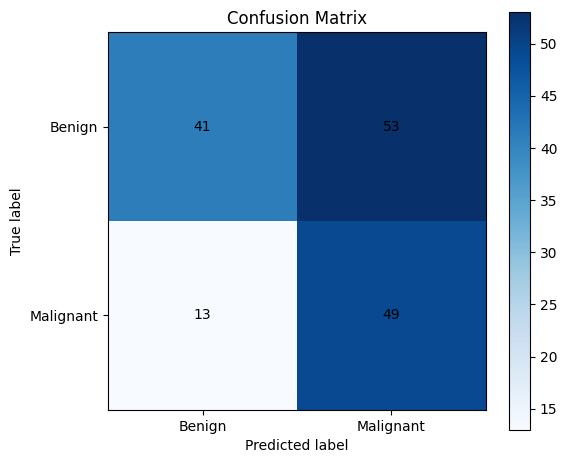

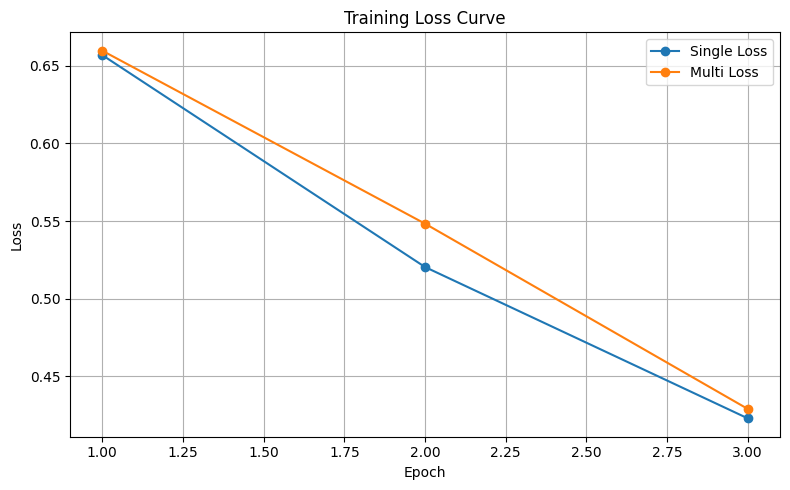

In [ ]:
# Uses train_loader and test_loader
EPOCHS = 3
single_losses = []
multi_losses = []
for e in range(EPOCHS):
    single_loss = train_single(train_loader)
    multi_loss = train_epoch(train_loader)
    single_losses.append(single_loss)
    multi_losses.append(multi_loss)
    print(f'Epoch {e+1}: Single Loss={single_loss:.4f} | Multi Loss={multi_loss:.4f}')

print('Single Accuracy:', evaluate_single(test_loader))
print('Multi Accuracy :', evaluate(test_loader))

y_true = []
y_pred = []
model.eval()
with torch.no_grad():
    for cc, mlo, y in test_loader:
        cc, mlo, y = cc.to(device), mlo.to(device), y.to(device)
        out = model(cc, mlo)
        pred = torch.argmax(out, 1)
        y_true.extend(y.cpu().numpy())
        y_pred.extend(pred.cpu().numpy())

cm = confusion_matrix(y_true, y_pred)
fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(cm, cmap='Blues')
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        ax.text(j, i, cm[i, j], ha='center', va='center', color='black')
ax.set_xticks([0, 1])
ax.set_xticklabels(['Benign', 'Malignant'])
ax.set_yticks([0, 1])
ax.set_yticklabels(['Benign', 'Malignant'])
ax.set_xlabel('Predicted label')
ax.set_ylabel('True label')
ax.set_title('Confusion Matrix')
fig.colorbar(im, ax=ax)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(range(1, EPOCHS + 1), single_losses, marker='o', label='Single Loss')
ax.plot(range(1, EPOCHS + 1), multi_losses, marker='o', label='Multi Loss')
ax.set_xlabel('Epoch')
ax.set_ylabel('Loss')
ax.set_title('Training Loss Curve')
ax.legend()
ax.grid(True)
plt.tight_layout()
plt.show()

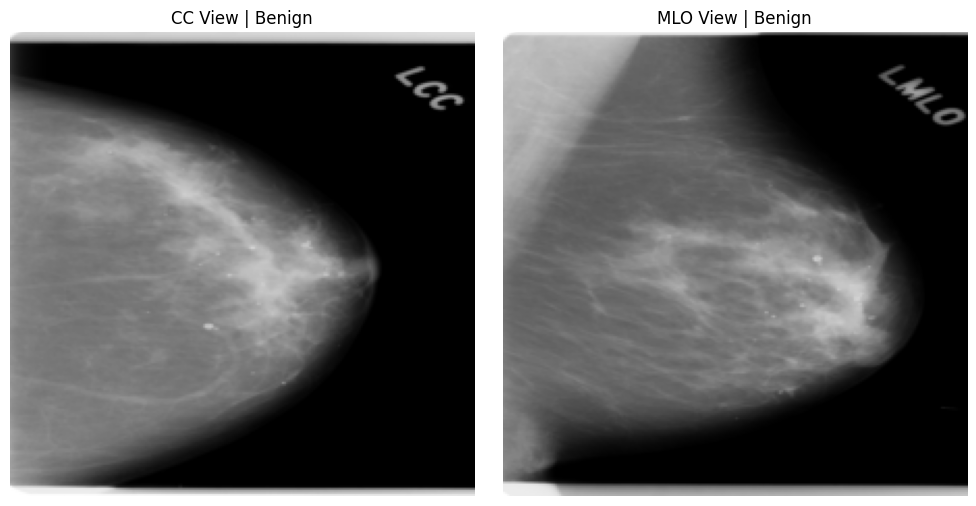

In [14]:
sample_idx = np.random.randint(len(train_dataset))
sample_cc, sample_mlo, sample_y = train_dataset[sample_idx]
sample_cc = sample_cc.mul(0.5).add(0.5).clamp(0, 1)
sample_mlo = sample_mlo.mul(0.5).add(0.5).clamp(0, 1)
label_text = 'Malignant' if sample_y == 1 else 'Benign'

fig, ax = plt.subplots(1, 2, figsize=(10, 5))
ax[0].imshow(sample_cc.permute(1, 2, 0))
ax[0].set_title(f'CC View | {label_text}')
ax[0].axis('off')

ax[1].imshow(sample_mlo.permute(1, 2, 0))
ax[1].set_title(f'MLO View | {label_text}')
ax[1].axis('off')

plt.tight_layout()